In [1]:
# Necessary imports #

# General #

import numpy as np
from scipy import integrate
import matplotlib.pyplot as plt
from scipy.interpolate import interp1d
from scipy import integrate
from copy import deepcopy
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import (
    RBF, Matern, RationalQuadratic, ExpSineSquared,
    DotProduct, ConstantKernel as C
)
import sys
import os

repo_root = os.path.abspath(os.path.join(os.getcwd(), ".."))
sys.path.append(repo_root)

# Cloelib #

from cloelib.cosmology.camb_cosmology import CAMBBackground, CAMBLinearPerturbations, CAMBNonLinearPerturbations
from cloelib.cosmology.HMcode2020Emu_cosmology import HMemuLinearPerturbations, HMemuNonLinearPerturbations
from cloelib.observables.photo import ShearTracer, PositionsTracer
from cloelib.summary_statistics.angular_two_point import AngularTwoPoint
from cloelib.summary_statistics.angular_correlation_function_wigner import AngularCorrelationFunctionWigner
import euclidlib as el
import seaborn as sns

# Gaussian processes #

from binz.run_gp import build_gp_nz 



/home/jipdebuck/miniconda3/envs/shared_env/lib/python3.12/site-packages/HMcode2020Emu
Loading linear emulator...


2025-11-24 10:28:02.188940: E external/local_xla/xla/stream_executor/cuda/cuda_platform.cc:51] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


Linear emulator loaded in memory.
Loading nonlinear emulator...
Non-linear emulator loaded in memory.
Loading linear emulator...
Baryonic boost emulator loaded in memory.
Loading sigma8 emulator...
Linear emulator loaded in memory.


## Preparing and plotting the original $n(z)$ from the Euclid overview

In [2]:
# Import and prepare original n(z) distribution #

zs = np.linspace(1e-4, 3, 100)
z, nz = el.photo.redshift_distributions('/home/jipdebuck/nzTabSPV3.fits')

def normalize_dndz(nz_example, z_nz):
    normalized = {}
    for key in nz_example:
        normalized[key] = nz_example[key] / integrate.trapezoid(nz_example[key], z_nz)
    return normalized

# Normalize both dndz_pos and dndz_she
dndz_pos_norm = normalize_dndz(nz, z)
dndz_she_norm = normalize_dndz(nz, z)

# Function to resample the normalized dndz
def resample_dndz(nz_example, z_nz, myz):
    my_dndz = np.vstack(list(nz_example.values())) #stacking arrays vertically
    my_dndz_norm = np.zeros([len(nz_example), len(myz)]) #creating an empty array
    for i in range(len(nz_example)):
        my_dndz_norm[i, :] = np.interp(myz, z_nz, my_dndz[i, :]) #interpolating to new myz values
    return my_dndz_norm

# Resampling the normalized dndz with 100 values
my_dndz_pos_norm = resample_dndz(dndz_pos_norm, z, zs)
my_dndz_she_norm = resample_dndz(dndz_she_norm, z, zs)

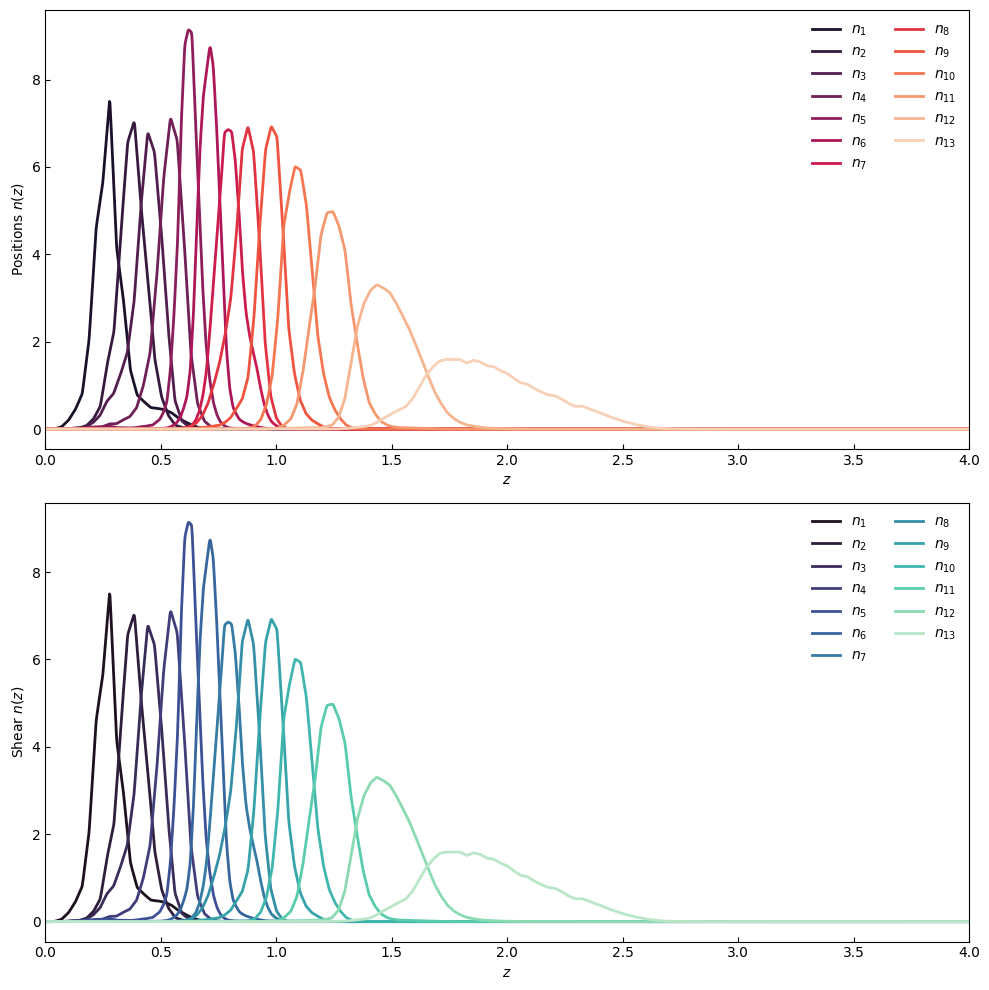

In [3]:
# Plotting of original n(z) distributions #

fig, axs = plt.subplots(2, 1, figsize=(10, 10))

# Customize tick parameters for both axes
for ax in axs.flatten():
    ax.tick_params(axis='both', which='both', direction='in')

# Plot positions n(z)
for i, (key, color) in enumerate(zip(dndz_pos_norm.keys(), sns.color_palette("rocket", len(dndz_pos_norm)))):
    axs[0].plot(z, dndz_pos_norm[key], label=f'$n_{{{i+1}}}$', linewidth=2, color=color)

# Plot shear n(z)
for j, (key, color) in enumerate(zip(dndz_she_norm.keys(), sns.color_palette("mako", len(dndz_she_norm)))):
    axs[1].plot(z, dndz_she_norm[key], label=f'$n_{{{j+1}}}$', linewidth=2, color=color)

# Set labels and legends
axs[0].set_xlabel(r'$z$')
axs[0].set_ylabel(r'Positions $n(z)$')
axs[0].set_xlim(0, 4)
axs[0].legend(frameon=False, ncol=2)

axs[1].set_xlabel(r'$z$')
axs[1].set_ylabel(r'Shear $n(z)$')
axs[1].set_xlim(0, 4)
axs[1].legend(frameon=False, ncol=2)

plt.tight_layout()
plt.show()


## Reconstruct $n(z)$ using Gaussian processes

In [16]:
# Define parameters for GP reconstruction #

z_meds = []   # positions of median redshift for each bin
n_meds = []   # height of n(z) at median redshift for each bin

for key, nz in dndz_she_norm.items():
    # --- CDF & median node ---
    cdf = integrate.cumulative_trapezoid(nz, z, initial=0)
    cdf /= cdf[-1]
    z_med = np.interp(0.5, cdf, z)
    n_med = nz[np.argmin(np.abs(z - z_med))]
    z_meds.append(z_med)
    n_meds.append(n_med)

corr_len = 0.03                                # correlation length for the GP kernel
z_bounds = (0,3)                              # bounds for the redshift
z_pred = np.linspace(0, 3, 400)       # prediction points for GP
alpha = 1e-8                                  # noise level during fitting 
kernel_class = Matern
nu = 1.5                                      # necessary for Matern only, defines smoothness 
const_value = 0.04                            # amplitude of constant kernel
const_bounds = (1e-4, 1.0)                    # bounds for constant kernel amplitude

print(z_meds)


[0.27590319200705216, 0.37661359871457145, 0.44582911661616964, 0.5424196600268599, 0.6214748503007049, 0.7093980587467854, 0.7985657466455814, 0.8666609162525956, 0.9779689861106543, 1.0913635344559958, 1.2432247853949816, 1.4793166612176567, 1.892923608652228]


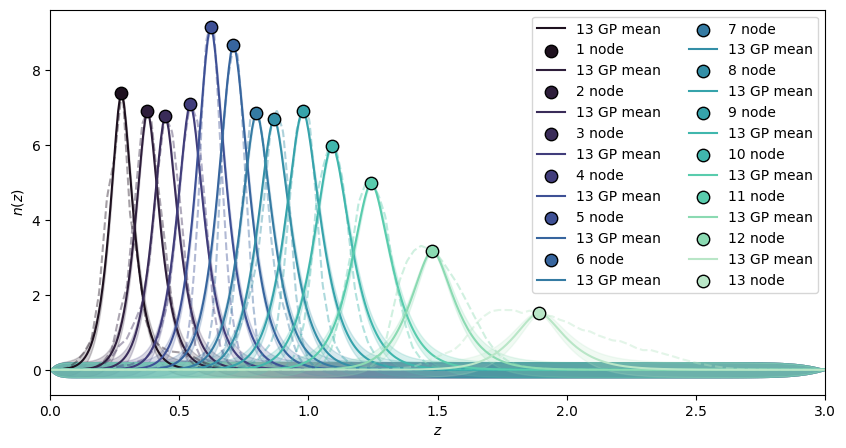

In [5]:
# GP reconstruction and plotting of results #

# Perform GP reconstruction #
priors, predictions = build_gp_nz(n_meds, z_meds, corr_len, z_bounds, z_pred, alpha, kernel_class, nu, const_value, const_bounds)

# Plot GP reconstruction results #
palette = sns.color_palette("mako", 13)
fig, ax = plt.subplots(figsize=(10, 5))

for j, nz in enumerate(n_meds):
    y_pred, y_std = predictions[j]
    X_train, y_train = z_meds[j], n_meds[j]

    ax.plot(z_pred, y_pred, color=palette[j], label=f"{key} GP mean")
    ax.fill_between(z_pred.ravel(), (y_pred - y_std).ravel(), (y_pred + y_std).ravel(),
                    color=palette[j], alpha=0.2)

    ax.plot(z, dndz_she_norm[j+1], '--', color=palette[j], alpha=0.4)
    ax.scatter(X_train, y_train, color=palette[j], edgecolor='black', s=80, zorder=3, label=f"{j+1} node")

ax.set_xlabel(r"$z$")
ax.set_ylabel(r"$n(z)$")
ax.set_xlim(0, 3)
ax.legend(loc="upper right", ncol=2)
plt.show()


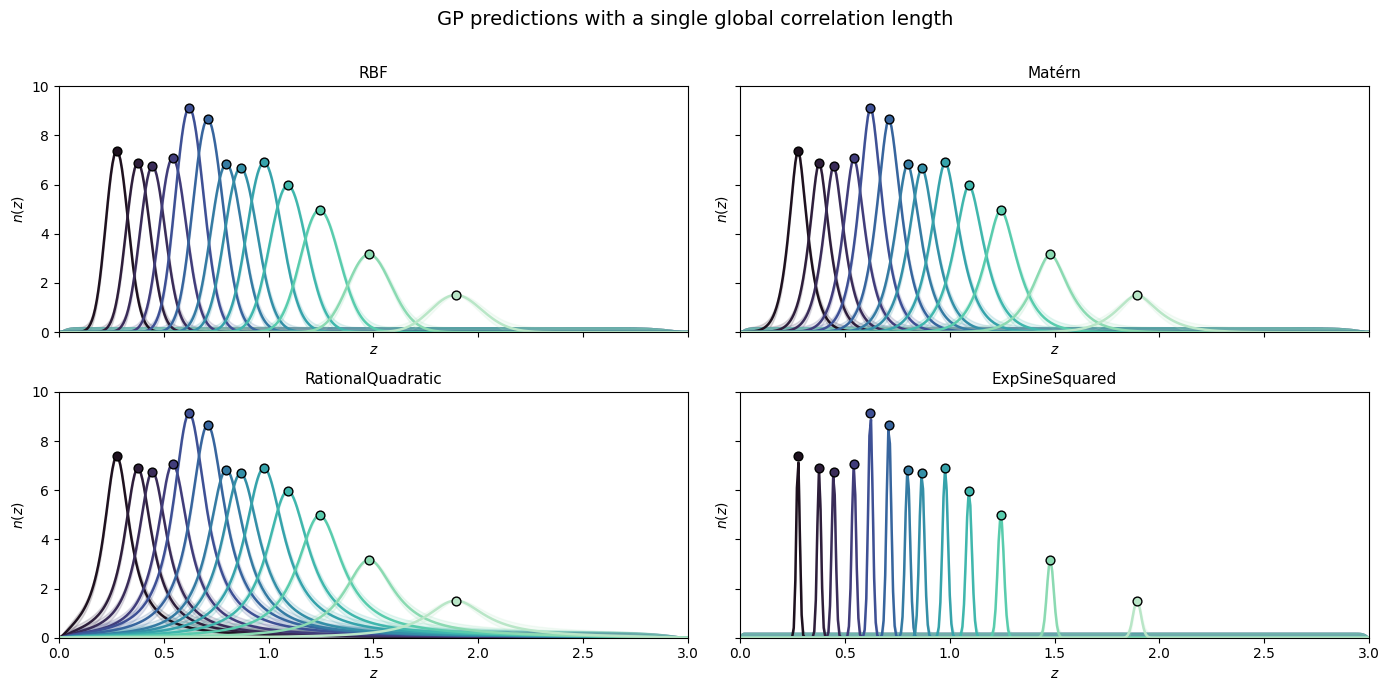

In [6]:
# Results using different kernels #

# Define different kernels #
kernel_dict = {
    "RBF": RBF,
    "Matérn": Matern,
    "RationalQuadratic": RationalQuadratic,
    "ExpSineSquared": ExpSineSquared
}

# Initialize figure for plotting #
n_kernels = len(kernel_dict)
palette = sns.color_palette("mako", len(dndz_she_norm))

fig, axs = plt.subplots(nrows=int(np.ceil(n_kernels/2)), ncols=2,
                        figsize=(14, 3.5 * int(np.ceil(n_kernels/2))),
                        sharex=True, sharey=True)
axs = axs.flatten()

# Compute and plot GP predictions for each kernel #
for ax, (kname, kernel) in zip(axs, kernel_dict.items()):
    
    z_meds = []
    n_meds = []
    for j, (key, nz) in enumerate(dndz_she_norm.items()):
        # --- Compute CDF and median node ---
        cdf = integrate.cumulative_trapezoid(nz, z, initial=0)
        cdf /= cdf[-1]
        z_med = np.interp(0.5, cdf, z)
        n_med = nz[np.argmin(np.abs(z - z_med))]
        z_meds.append(z_med)
        n_meds.append(n_med)

    
    gp_prior, gp_pred = build_gp_nz(n_meds, z_meds, corr_len, z_bounds, z_pred, alpha, kernel, nu, const_value, const_bounds)

    for j, nz in enumerate(n_meds):
        y_pred, y_std = gp_pred[j]
        ax.plot(z_pred, y_pred, color=palette[j], label=f"{key} mean", lw=1.8)
        ax.fill_between(z_pred.ravel(), (y_pred - y_std).ravel(),
                        (y_pred + y_std).ravel(), color=palette[j], alpha=0.15)
        ax.scatter(z_meds[j], nz, color=palette[j], edgecolor='black', s=40, zorder=3)

        ax.set_title(kname, fontsize=11)
        ax.set_xlim(0, 3)
        ax.set_ylim(0,10)
        ax.set_xlabel(r"$z$")
        ax.set_ylabel(r"$n(z)$")

for ax in axs[len(kernel_dict):]:
    ax.axis("off")

fig.suptitle("GP predictions with a single global correlation length", fontsize=14)
plt.tight_layout(rect=[0, 0, 1, 0.97])
plt.show()


## Compute $C_{\ell}$'s using the reconstructed $n(z)$

In [7]:
# Compute the C_ell's using the original n(z) #

# The arguments of the Background functions follow the cosmology.API
background = CAMBBackground(H0=70.0, 
                            Omega_cdm0=0.25, 
                            Omega_b0=0.05, 
                            w0=-1, 
                            wa=0, 
                            Omega_k0 = 0.0, 
                            ns = 0.96, 
                            As = 2e-9,
                            mnu = 0.06,
                            gamma_MG = 0.545,
                            N_mnu = 1)
linear_perturbations_emu = HMemuLinearPerturbations(background, zs)
nonlinear_perturbations_emu = HMemuNonLinearPerturbations(background, linear_perturbations_emu, zs, log10TAGN=7.8)

# Select the perturbations object you want to use
perturbations = nonlinear_perturbations_emu

# Define the tracers
tracer_pos = PositionsTracer(perturbations=perturbations, 
                             dndz=my_dndz_pos_norm,
                             z = zs,
                             galaxy_bias_model='poly',
                             nuisance_params={'b1_photo_poly0': 1.0, 'b1_photo_poly1': 0.0, 
                                              'b1_photo_poly2': 0.0, 'b1_photo_poly3': 0.0,
                                              'magnification_bias_1': 0.0, 'magnification_bias_2': 0.0,
                                              'magnification_bias_3': 0.0, 'magnification_bias_4': 0.0,
                                              'magnification_bias_5': 0.0, 'magnification_bias_6': 0.0,
                                              'magnification_bias_7': 0.0, 'magnification_bias_8': 0.0,
                                              'magnification_bias_9': 0.0, 'magnification_bias_10': 0.0,
                                              'magnification_bias_11': 0.0, 'magnification_bias_12': 0.0,
                                              'magnification_bias_13': 0.0,
                                              'dz_pos_1': 0.0001, 'dz_pos_2': 0.0001,
                                              'dz_pos_3': 0.0001, 'dz_pos_4': 0.0001,
                                              'dz_pos_5': 0.0001, 'dz_pos_6': 0.0001,
                                              'dz_pos_7': 0.0001, 'dz_pos_8': 0.0001,
                                              'dz_pos_9': 0.0001, 'dz_pos_10': 0.0001,
                                              'dz_pos_11': 0.0001, 'dz_pos_12': 0.0001,
                                              'dz_pos_13': 0.0001})

tracer_she = ShearTracer(perturbations=perturbations, 
                             dndz=my_dndz_she_norm,
                             z = zs,
                             nuisance_params={'AIA': 1.72, 'CIA': 0.0134, 'EtaIA':-0.41,
                                              'multiplicative_bias_1': 0.001, 'multiplicative_bias_2': 0.001,
                                              'multiplicative_bias_3': 0.001, 'multiplicative_bias_4': 0.001,
                                              'multiplicative_bias_5': 0.001, 'multiplicative_bias_6': 0.001,
                                              'multiplicative_bias_7': 0.001, 'multiplicative_bias_8': 0.001,
                                              'multiplicative_bias_9': 0.001, 'multiplicative_bias_10': 0.001,
                                              'multiplicative_bias_11': 0.001, 'multiplicative_bias_12': 0.001,
                                              'multiplicative_bias_13': 0.001,
                                              'dz_shear_1': 0.0001, 'dz_shear_2': 0.0001,
                                              'dz_shear_3': 0.0001, 'dz_shear_4': 0.0001,
                                              'dz_shear_5': 0.0001, 'dz_shear_6': 0.0001,
                                              'dz_shear_7': 0.0001, 'dz_shear_8': 0.0001,
                                              'dz_shear_9': 0.0001, 'dz_shear_10': 0.0001,
                                              'dz_shear_11': 0.0001, 'dz_shear_12': 0.0001,
                                              'dz_shear_13': 0.0001})

In [8]:
# Resampling reconstructed n(z) #

z_pred_res = z_pred.reshape(-1, 1)
def resample_dndz_gp(gp_predictions, z_pred, zs):
    for key in gp_predictions.keys():
        gp_predictions[key] = gp_predictions[key][0]

    my_dndz = np.vstack(list(gp_predictions.values())) 
    my_dndz_norm = np.zeros([len(gp_predictions), len(zs)])
    for i in range(len(gp_predictions)):
        # gp_predictions[i][0] is 1D array of n(z) for bin i

        my_dndz_norm[i, :] = np.interp(zs, z_pred[:,0], my_dndz[i, :])
    
    return my_dndz_norm

my_dndz_norm_gp = resample_dndz_gp(predictions, z_pred_res, zs)



In [9]:
# Compute the C_ell's using the reconstructed n(z) #

tracer_pos_gp = PositionsTracer(perturbations=perturbations, 
                             dndz=my_dndz_norm_gp,  
                             z = zs,
                             galaxy_bias_model='poly',
                             nuisance_params={'b1_photo_poly0': 1.0, 'b1_photo_poly1': 0.0, 
                                              'b1_photo_poly2': 0.0, 'b1_photo_poly3': 0.0,
                                              'magnification_bias_1': 0.0, 'magnification_bias_2': 0.0,
                                              'magnification_bias_3': 0.0, 'magnification_bias_4': 0.0,
                                              'magnification_bias_5': 0.0, 'magnification_bias_6': 0.0,
                                              'magnification_bias_7': 0.0, 'magnification_bias_8': 0.0,
                                              'magnification_bias_9': 0.0, 'magnification_bias_10': 0.0,
                                              'magnification_bias_11': 0.0, 'magnification_bias_12': 0.0,
                                              'magnification_bias_13': 0.0,
                                              'dz_pos_1': 0.0001, 'dz_pos_2': 0.0001,
                                              'dz_pos_3': 0.0001, 'dz_pos_4': 0.0001,
                                              'dz_pos_5': 0.0001, 'dz_pos_6': 0.0001,
                                              'dz_pos_7': 0.0001, 'dz_pos_8': 0.0001,
                                              'dz_pos_9': 0.0001, 'dz_pos_10': 0.0001,
                                              'dz_pos_11': 0.0001, 'dz_pos_12': 0.0001,
                                              'dz_pos_13': 0.0001})

tracer_she_gp = ShearTracer(perturbations=perturbations, 
                             dndz=my_dndz_norm_gp,
                             z = zs,
                             nuisance_params={'AIA': 1.72, 'CIA': 0.0134, 'EtaIA':-0.41,
                                              'multiplicative_bias_1': 0.001, 'multiplicative_bias_2': 0.001,
                                              'multiplicative_bias_3': 0.001, 'multiplicative_bias_4': 0.001,
                                              'multiplicative_bias_5': 0.001, 'multiplicative_bias_6': 0.001,
                                              'multiplicative_bias_7': 0.001, 'multiplicative_bias_8': 0.001,
                                              'multiplicative_bias_9': 0.001, 'multiplicative_bias_10': 0.001,
                                              'multiplicative_bias_11': 0.001, 'multiplicative_bias_12': 0.001,
                                              'multiplicative_bias_13': 0.001,
                                              'dz_shear_1': 0.0001, 'dz_shear_2': 0.0001,
                                              'dz_shear_3': 0.0001, 'dz_shear_4': 0.0001,
                                              'dz_shear_5': 0.0001, 'dz_shear_6': 0.0001,
                                              'dz_shear_7': 0.0001, 'dz_shear_8': 0.0001,
                                              'dz_shear_9': 0.0001, 'dz_shear_10': 0.0001,
                                              'dz_shear_11': 0.0001, 'dz_shear_12': 0.0001,
                                              'dz_shear_13': 0.0001})



## Plot and compare window functions

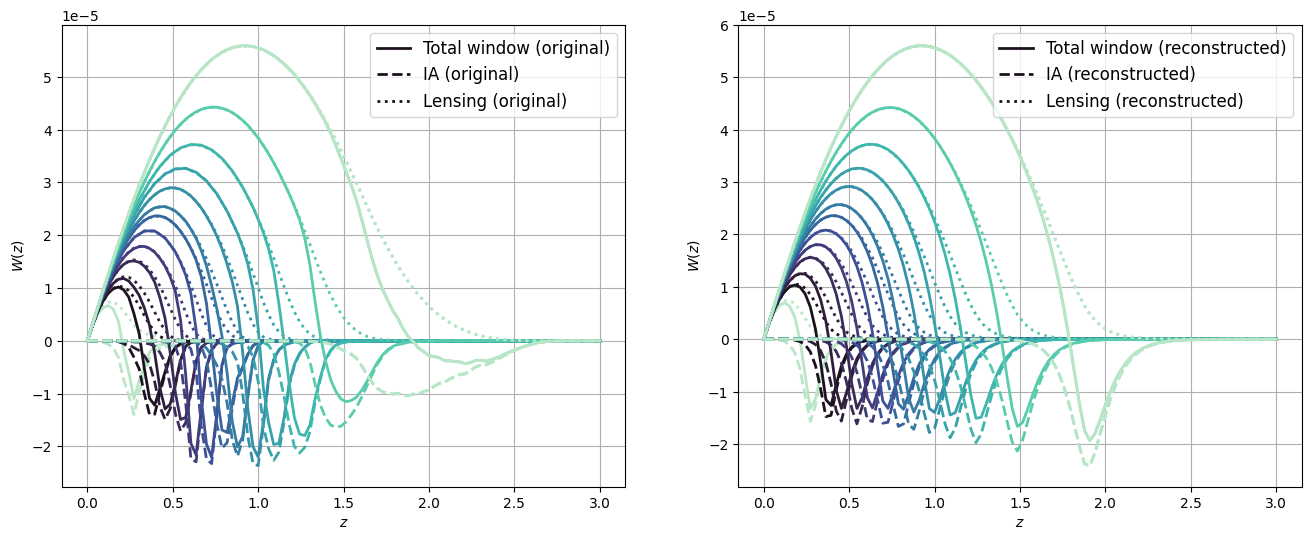

In [10]:
colors = sns.color_palette("mako", 13)

plt.figure(figsize=(16, 6))

plt.subplot(1,2,1)

for i in range(0, 14):
    # Plot the window
    plt.plot(perturbations.z, 
             tracer_she.get_window(perturbations.z)[i, :], 
             linewidth=2, 
             color=colors[i-1], 
             label=f'Total window (original)' if i == 1 else "")
    
    # Plot the intrinsic alignment window
    plt.plot(perturbations.z, 
             tracer_she.get_window_IA(perturbations.z)[i, :], 
             linewidth=2, 
             linestyle='--', 
             color=colors[i-1], 
             label=f'IA (original)' if i == 1 else "")
    
    # Plot the lensing window
    plt.plot(perturbations.z, 
             tracer_she.get_window_lensing(perturbations.z)[i, :], 
             linewidth=2, 
             linestyle=':', 
             color=colors[i-1], 
             label=f'Lensing (original)' if i == 1 else "")

# Label the axes
plt.xlabel(r'$z$')
plt.ylabel(r'$W(z)$')

# Add the legend and grid
plt.legend(fontsize=12, loc='upper right')
plt.grid(True)

plt.subplot(1,2,2)

for i in range(0, 14):
    # Plot the window
    plt.plot(perturbations.z, 
             tracer_she_gp.get_window(perturbations.z)[i, :], 
             linewidth=2, 
             color=colors[i-1], 
             label=f'Total window (reconstructed)' if i == 1 else "")
    
    # Plot the intrinsic alignment window
    plt.plot(perturbations.z, 
             tracer_she_gp.get_window_IA(perturbations.z)[i, :], 
             linewidth=2, 
             linestyle='--', 
             color=colors[i-1], 
             label=f'IA (reconstructed)' if i == 1 else "")
    
    # Plot the lensing window
    plt.plot(perturbations.z, 
             tracer_she_gp.get_window_lensing(perturbations.z)[i, :], 
             linewidth=2, 
             linestyle=':', 
             color=colors[i-1], 
             label=f'Lensing (reconstructed)' if i == 1 else "")

# Label the axes
plt.xlabel(r'$z$')
plt.ylabel(r'$W(z)$')

# Add the legend and grid
plt.legend(fontsize=12, loc='upper right')
plt.grid(True)


# Show the plot
plt.show()


## Plot and compare $C_{\ell}$'s computed using original and reconstructed $n(z)$

In [11]:
# Compute angular two-point statistics #

nl = 100
ells = np.logspace(1., np.log10(3000), nl)

twopoint_pospos = AngularTwoPoint(tracer_pos, tracer_pos)
twopoint_shepos = AngularTwoPoint(tracer_she, tracer_pos)
twopoint_posshe = AngularTwoPoint(tracer_pos, tracer_she)
twopoint_sheshe = AngularTwoPoint(tracer_she, tracer_she)

cells ={**twopoint_pospos.get_Cl(ells, 0, perturbations.k)
, **twopoint_shepos.get_Cl(ells, 0, perturbations.k)
, **twopoint_sheshe.get_Cl(ells, 0, perturbations.k)}

twopoint_pospos_gp = AngularTwoPoint(tracer_pos_gp, tracer_pos_gp)
twopoint_shepos_gp = AngularTwoPoint(tracer_she_gp, tracer_pos_gp)
twopoint_posshe_gp = AngularTwoPoint(tracer_pos_gp, tracer_she_gp)
twopoint_sheshe_gp = AngularTwoPoint(tracer_she_gp, tracer_she_gp)

cells_gp ={**twopoint_pospos_gp.get_Cl(ells, 0, perturbations.k)
, **twopoint_shepos_gp.get_Cl(ells, 0, perturbations.k)
, **twopoint_sheshe_gp.get_Cl(ells, 0, perturbations.k)}

<>:15: SyntaxWarning: invalid escape sequence '\e'
<>:24: SyntaxWarning: invalid escape sequence '\e'
<>:15: SyntaxWarning: invalid escape sequence '\e'
<>:24: SyntaxWarning: invalid escape sequence '\e'
/tmp/ipykernel_1119/1577694599.py:15: SyntaxWarning: invalid escape sequence '\e'
  axes[0].set_title("Old $n(z)$ (dashed lines) vs new $n(z)$ (solid lines) $C^{gg}(\ell)$'s", fontsize=14)
/tmp/ipykernel_1119/1577694599.py:24: SyntaxWarning: invalid escape sequence '\e'
  axes[1].set_title("Relative difference between old $n(z)$ and new $n(z)$ $C^{gg}(\ell)$'s", fontsize=14)


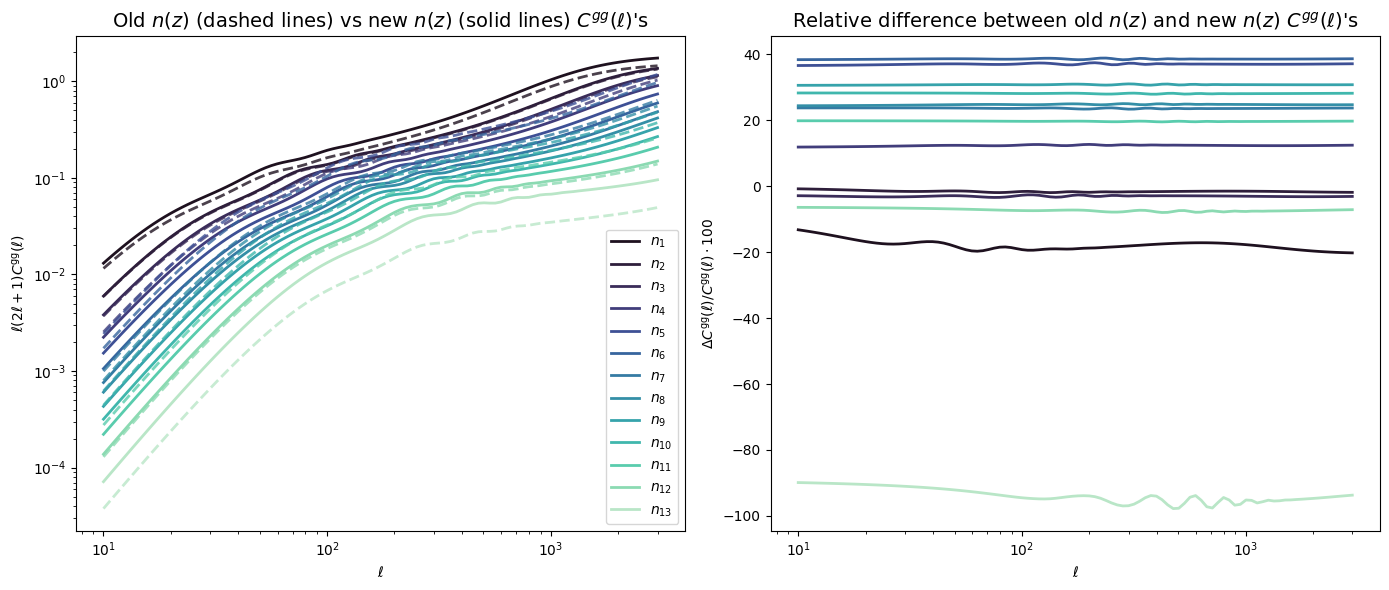

In [12]:
# Plot POS-POS C_ell's comparison #

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

for i in range(0, 13):
    ells = cells_gp['POS', 'POS', i+1, i+1].ell
    axes[0].loglog(ells, ells*(2*ells+1)*cells_gp['POS', 'POS', i+1, i+1], label = '$n_{{{}}}$'.format(i+1), linewidth=2, color=colors[i])

for i in range(0, 13):
    ells = cells['POS', 'POS', i+1, i+1].ell
    axes[0].loglog(ells, ells*(2*ells+1)*cells['POS', 'POS', i+1, i+1], linestyle='--', alpha=0.8, linewidth=2, color=colors[i])
    
axes[0].set_xlabel(r'$\ell$')
axes[0].set_ylabel(r'$\ell (2\ell +1)C^{\rm gg}(\ell)$');
axes[0].set_title("Old $n(z)$ (dashed lines) vs new $n(z)$ (solid lines) $C^{gg}(\ell)$'s", fontsize=14)
axes[0].legend(fontsize=10, loc='lower right', frameon=True)

for i in range(0,13):
    ells = cells['POS', 'POS', i+1, i+1].ell
    cells_diff = 100*(np.asarray(cells['POS', 'POS', i+1, i+1]) - np.asarray(cells_gp['POS', 'POS', i+1, i+1])) / (np.asarray(cells['POS', 'POS', i+1, i+1]))
    axes[1].semilogx(ells, cells_diff, label = '$n_{{{}}}$'.format(i+1), linewidth=2, color=colors[i])
axes[1].set_xlabel(r'$\ell$')
axes[1].set_ylabel(r'$\Delta C^{\rm gg}(\ell)/C^{\rm gg}(\ell)\cdot 100$')
axes[1].set_title("Relative difference between old $n(z)$ and new $n(z)$ $C^{gg}(\ell)$'s", fontsize=14)


plt.subplots_adjust(right=0.95, wspace=0.15)
plt.tight_layout()
plt.show()

<>:14: SyntaxWarning: invalid escape sequence '\e'
<>:23: SyntaxWarning: invalid escape sequence '\e'
<>:14: SyntaxWarning: invalid escape sequence '\e'
<>:23: SyntaxWarning: invalid escape sequence '\e'
/tmp/ipykernel_1119/1511158525.py:14: SyntaxWarning: invalid escape sequence '\e'
  axes[0].set_title("Old $n(z)$ (dashed lines) vs new $n(z)$ (solid lines) $C^{EE}(\ell)$'s", fontsize=14)
/tmp/ipykernel_1119/1511158525.py:23: SyntaxWarning: invalid escape sequence '\e'
  axes[1].set_title("Relative difference between old $n(z)$ and new $n(z)$ $C^{EE}(\ell)$'s", fontsize=14)


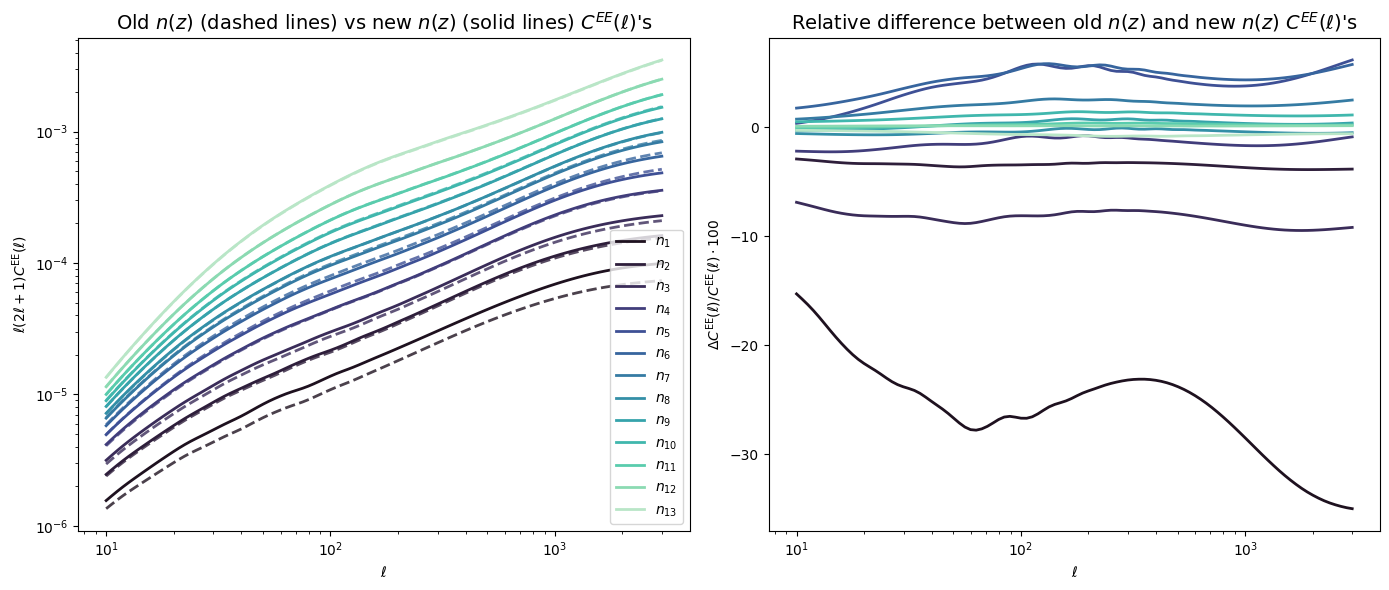

In [13]:
# Plot SHE-SHE C_ell's comparison #

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

for i in range(0, 13):
    ells = cells_gp['SHE', 'SHE', i+1, i+1].ell
    axes[0].loglog(ells, ells*(2*ells+1)*cells_gp['SHE', 'SHE', i+1, i+1][0,0], label = '$n_{{{}}}$'.format(i+1), linewidth=2, color=colors[i])

for i in range(0, 13):
    ells = cells['SHE', 'SHE', i+1, i+1].ell
    axes[0].loglog(ells, ells*(2*ells+1)*cells['SHE', 'SHE', i+1, i+1][0,0], linestyle='--', alpha=0.8, linewidth=2, color=colors[i])
axes[0].set_xlabel(r'$\ell$')
axes[0].set_ylabel(r'$\ell (2\ell +1)C^{\rm EE}(\ell)$');
axes[0].set_title("Old $n(z)$ (dashed lines) vs new $n(z)$ (solid lines) $C^{EE}(\ell)$'s", fontsize=14)
axes[0].legend(fontsize=10, loc='lower right', frameon=True)

for i in range(0,13):
    ells = cells['SHE', 'SHE', i+1, i+1].ell
    cells_diff = 100*(np.asarray(cells['SHE', 'SHE', i+1, i+1][0,0]) - np.asarray(cells_gp['SHE', 'SHE', i+1, i+1][0,0])) / (np.asarray(cells['SHE', 'SHE', i+1, i+1][0,0]))
    axes[1].semilogx(ells, cells_diff, label = '$n_{{{}}}$'.format(i+1), linewidth=2, color=colors[i])
axes[1].set_xlabel(r'$\ell$')
axes[1].set_ylabel(r'$\Delta C^{\rm EE}(\ell)/C^{\rm EE}(\ell)\cdot 100$')
axes[1].set_title("Relative difference between old $n(z)$ and new $n(z)$ $C^{EE}(\ell)$'s", fontsize=14)
#handles, labels = axes[0].get_legend_handles_labels()
#fig.legend(handles, labels, loc='center right')

# Adjust layout so legend fits nicely
plt.subplots_adjust(right=0.85, wspace=0.25)
plt.tight_layout()
plt.show()

<>:14: SyntaxWarning: invalid escape sequence '\e'
<>:25: SyntaxWarning: invalid escape sequence '\e'
<>:14: SyntaxWarning: invalid escape sequence '\e'
<>:25: SyntaxWarning: invalid escape sequence '\e'
/tmp/ipykernel_1119/705577231.py:14: SyntaxWarning: invalid escape sequence '\e'
  axes[0].set_title("Old $n(z)$ (dashed lines) vs new $n(z)$ (solid lines) $C^{gE}(\ell)$'s", fontsize=14)
/tmp/ipykernel_1119/705577231.py:25: SyntaxWarning: invalid escape sequence '\e'
  axes[1].set_title("Relative difference between old $n(z)$ and new $n(z)$ $C^{gE}(\ell)$'s", fontsize=14)


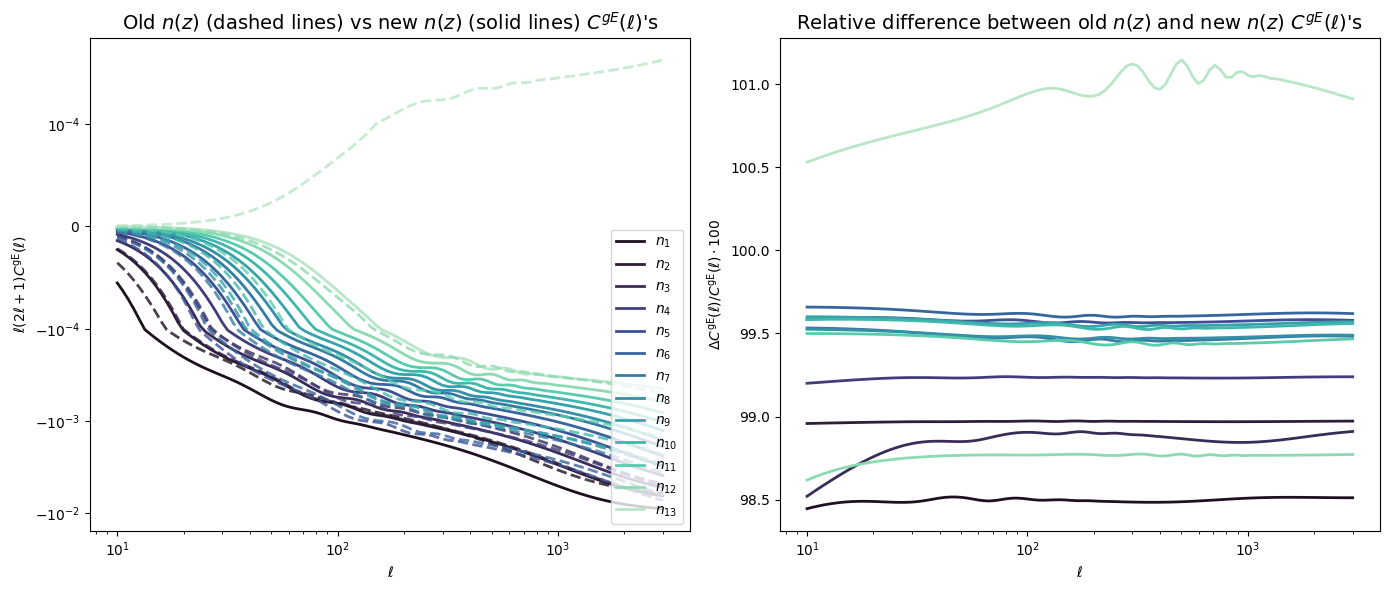

In [14]:
# Plot POS-SHE C_ell's comparison #

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

for i in range(0, 13):
    ells = cells_gp['POS', 'SHE', i+1, i+1].ell
    axes[0].loglog(ells, ells*(2*ells+1)*cells_gp['POS', 'SHE', i+1, i+1][0], label = '$n_{{{}}}$'.format(i+1), linewidth=2, color=colors[i])

for i in range(0, 13):
    ells = cells['POS', 'SHE', i+1, i+1].ell
    axes[0].loglog(ells, ells*(2*ells+1)*cells['POS', 'SHE', i+1, i+1][0], linestyle='--', alpha=0.8, linewidth=2, color=colors[i])
axes[0].set_xlabel(r'$\ell$')
axes[0].set_ylabel(r'$\ell (2\ell +1)C^{\rm gE}(\ell)$');
axes[0].set_title("Old $n(z)$ (dashed lines) vs new $n(z)$ (solid lines) $C^{gE}(\ell)$'s", fontsize=14)
axes[0].legend(fontsize=10, loc='lower right', frameon=True)
axes[0].set_yscale('symlog', linthresh=1e-4)
axes[0].set_xscale('log')

for i in range(0,13):
    ells = cells['POS', 'SHE', i+1, i+1].ell
    cells_diff = (100*np.asarray(cells['POS', 'SHE', i+1, i+1][0]) - np.asarray(cells_gp['POS', 'SHE', i+1, i+1][0])) / (np.asarray(cells['POS', 'SHE', i+1, i+1][0]))
    axes[1].semilogx(ells, cells_diff, label = '$n_{{{}}}$'.format(i+1), linewidth=2, color=colors[i])
axes[1].set_xlabel(r'$\ell$')
axes[1].set_ylabel(r'$\Delta C^{\rm gE}(\ell)/C^{\rm gE}(\ell)\cdot 100$')
axes[1].set_title("Relative difference between old $n(z)$ and new $n(z)$ $C^{gE}(\ell)$'s", fontsize=14)
#handles, labels = axes[0].get_legend_handles_labels()
#fig.legend(handles, labels, loc='center right')

# Adjust layout so legend fits nicely
plt.subplots_adjust(right=0.85, wspace=0.25)
plt.tight_layout()
plt.show()

KeyboardInterrupt: 

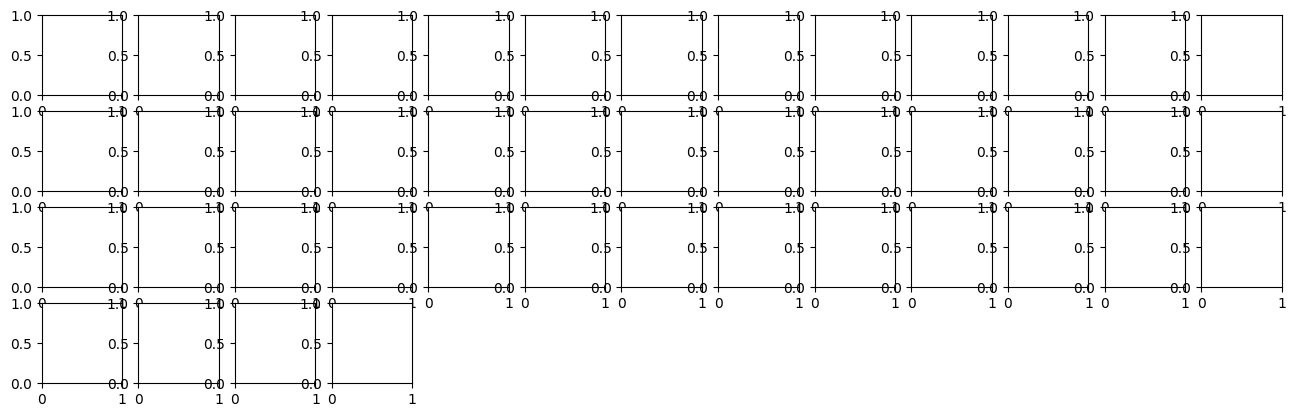

In [15]:
# Plot difference between Cells with every combination between redshift bins (this plot will be changed) #

fig, ax = plt.subplots(13, 13, figsize=(16, 16), sharex=True, sharey=True)

for i in range(1, 14):
    for j in range(1, i):
        ax[j - 1, i - 1].axis("off")
    for j in range(i, 14):
        ell = cells["SHE", "SHE",i, j].ell
        cell_diff = 100*(np.asarray(cells["SHE", "SHE",i, j][0, 0]) - np.asarray(cells_gp["SHE", "SHE",i, j][0, 0])) / (np.asarray(cells["SHE", "SHE",i, j][0, 0]))
        ax[j - 1, i - 1].plot(
            cells["SHE", "SHE",i, j].ell,
            cell_diff,
            c="black",
            lw=2,
            zorder=3.0
        )
    if (j >= 7) and (i >= 7):
            ax[j - 1, i - 1].set_ylim(-3, 3)
    else:
            ax[j - 1, i - 1].set_ylim(-15, 10)


ax[0, 0].set_xscale("log")
ax[0, 0].set_xlim(1 / 3, 1500)
ax[0, 0].xaxis.get_major_locator().set_params(numticks=10)
ax[0, 0].xaxis.get_minor_locator().set_params(
    numticks=10, subs=np.arange(0.1, 1.0, 0.1)
)
ax[0, 0].set_ylim(-15, 10)

for ax_i in ax.flat:
    ax_i.tick_params(axis='both', which='both', labelsize=10)


fig.subplots_adjust(left=0.0, bottom=0.0, right=1.0, top=1.0, wspace=0.0, hspace=0.0)

fig.supxlabel("angular mode $\\ell$", y=-0.05, va="top")
fig.supylabel(r'$\Delta C^{\rm EE}(\ell)/C^{\rm EE}(\ell)\cdot 100$', x=-0.1, ha="right")
plt.savefig("cells_sheshe.pdf", bbox_inches="tight")
plt.show()

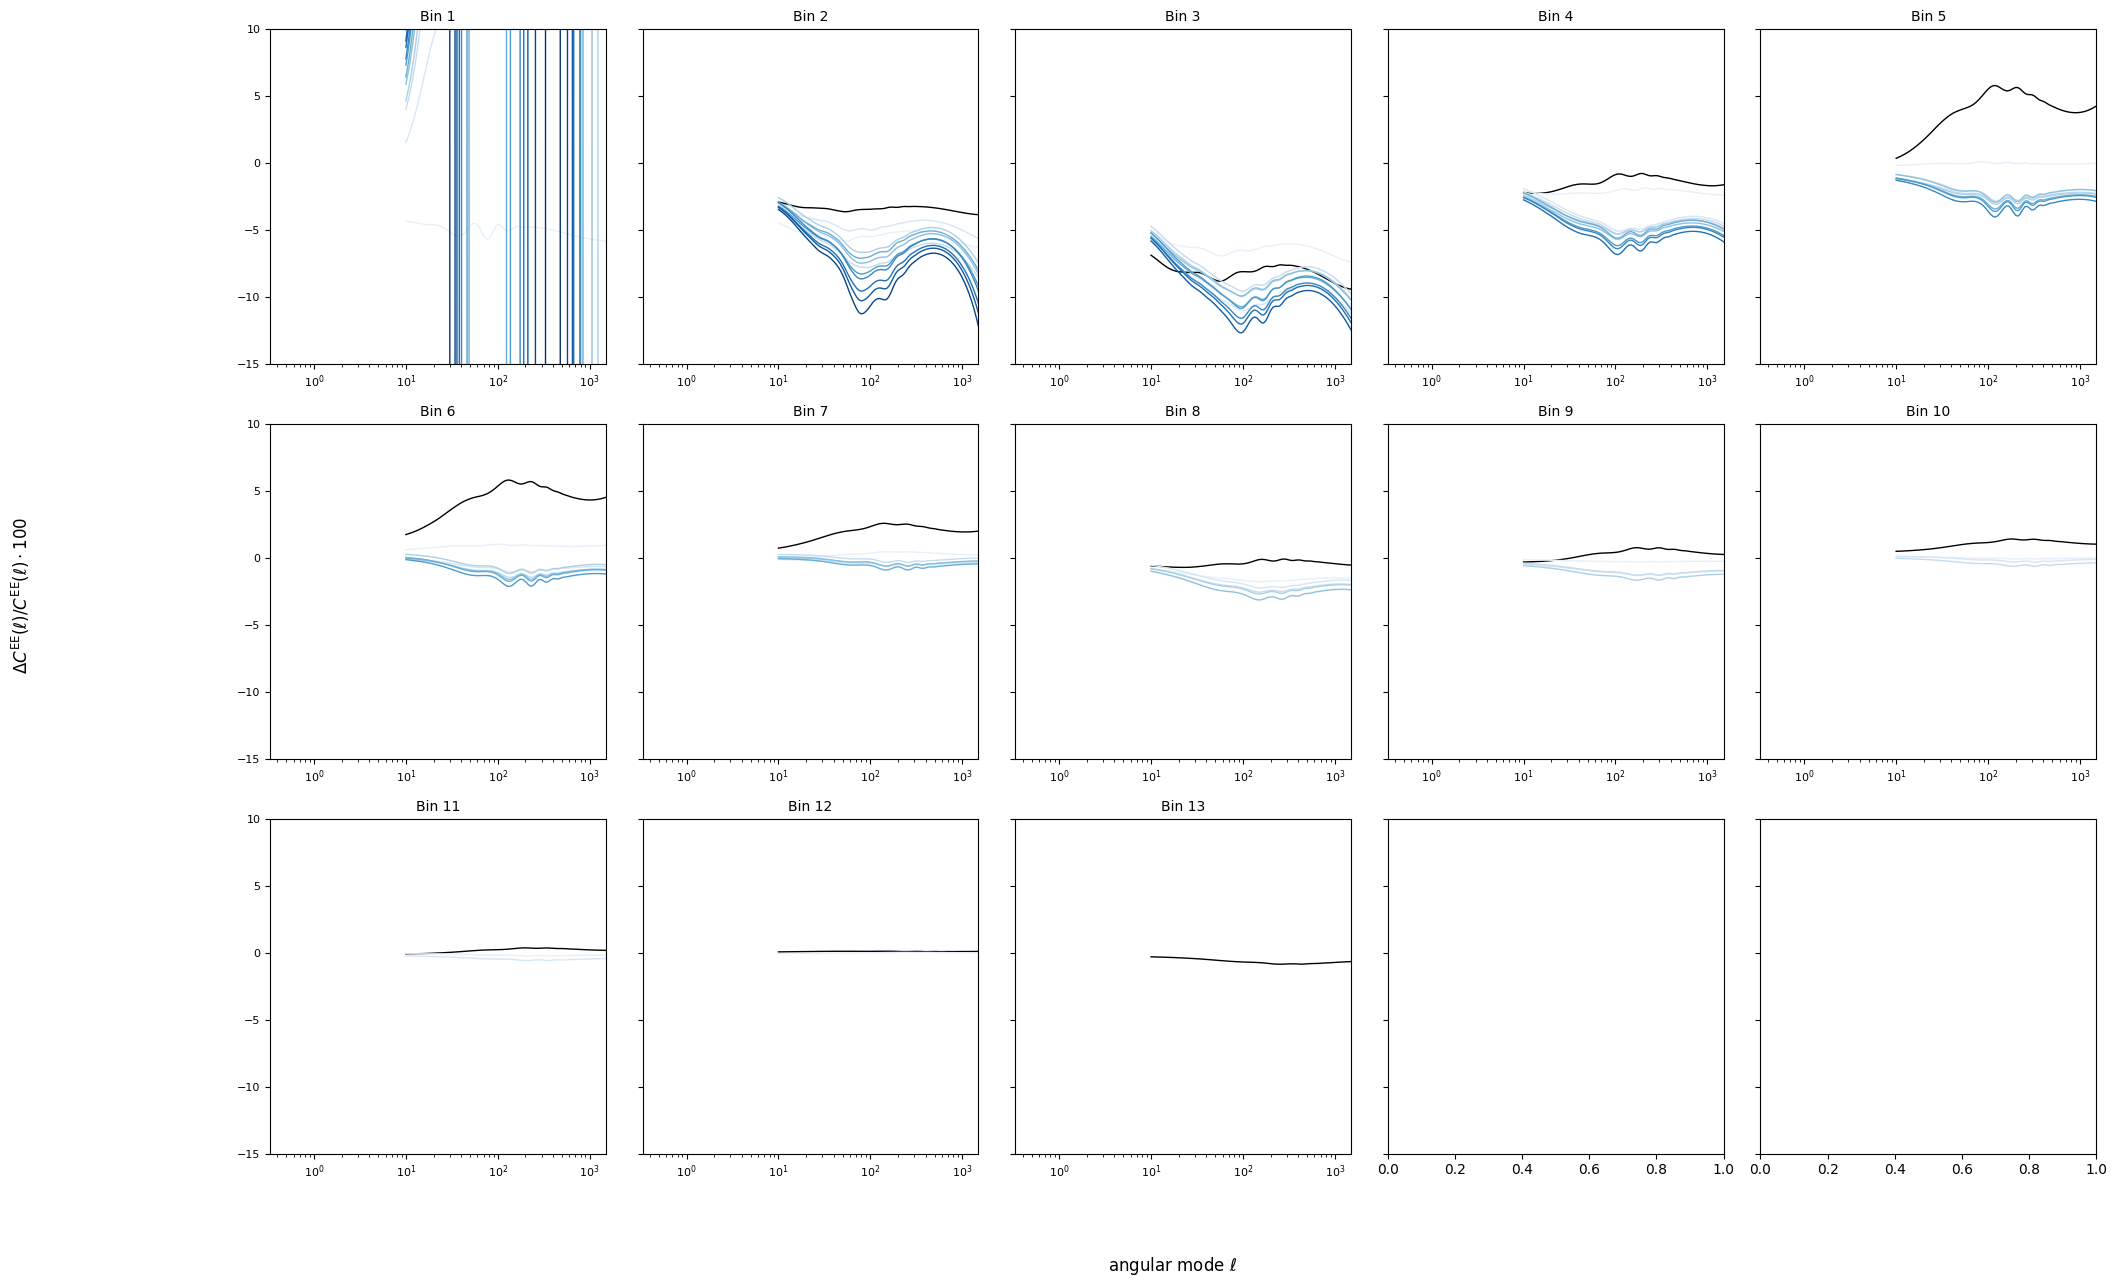

In [ ]:
n_bins = 13


cmap_neg = plt.cm.Oranges_r  
cmap_pos = plt.cm.Blues       

fig, axes = plt.subplots(3, 5, figsize=(19,12), sharey=True)

max_offset = n_bins - 1  

for i in range(1, n_bins + 1):
    for j in range(i, n_bins + 1):
        ax = axes[(i - 1) // 5, (i - 1) % 5]
        offset = j - i
        cell_diff = 100*(np.asarray(cells["SHE", "SHE",i, j][0, 0]) - np.asarray(cells_gp["SHE", "SHE",i, j][0, 0])) / (np.asarray(cells["SHE", "SHE",i, j][0, 0]))
        ell = cells["SHE","SHE",i,j].ell

        
        if offset > 0:
            color = cmap_pos(offset / max_offset)
        elif offset < 0:
            color = cmap_neg(-offset / max_offset)
        else:
            color = 'black'  # self-correlation

        ax.plot(ell, cell_diff, color=color, lw=1)

    ax.set_xscale("log")
    ax.set_xlim(1/3, 1500)
    ax.set_ylim(-15,10)
    ax.set_title(f'Bin {i}', fontsize=10)
    ax.tick_params(axis='both', labelsize=8)

fig.tight_layout()
fig.supxlabel("angular mode $\\ell$", y=-0.05, va="top")
fig.supylabel(r'$\Delta C^{\rm EE}(\ell)/C^{\rm EE}(\ell)\cdot 100$', x=-0.1, ha="right")
plt.show()
